# Linear regression

An assessment of how response shifts and a single influential observation affect an ordinary least-squares fit.

## Data and scope

The analysis uses 13 numeric pairs defined directly in the code. Predictor values range from 2 to 17; measurement units are unspecified. The reference code’s `stat`/`stats` naming inconsistency is corrected. No external data file is required.

## Environment

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
print('numpy', np.__version__, 'pandas', pd.__version__, 'scipy', scipy.__version__, 'sklearn', sklearn.__version__)
results = {}

numpy 2.4.4 pandas 3.0.2 scipy 1.17.1 sklearn 1.8.0


## Baseline analysis

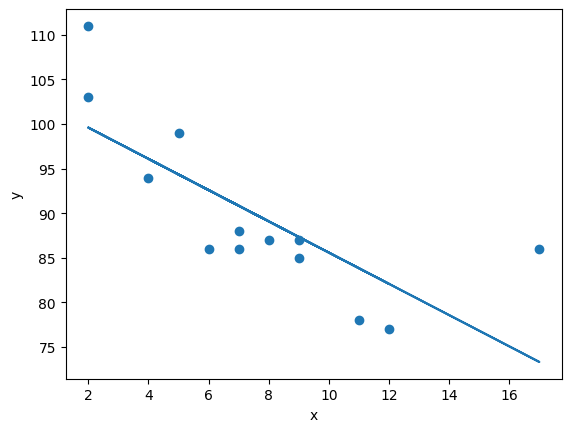

Pearsons correlation: -0.759


In [2]:
import matplotlib.pyplot as plt
from scipy import stats
x = [5, 7, 8, 7, 2, 17, 2, 9, 4, 11, 12, 9, 6]
y = [99, 86, 87, 88, 111, 86, 103, 87, 94, 78, 77, 85, 86]
slope, intercept, r, p, std_err = stats.linregress(x, y)
corr, _ = stats.pearsonr(x, y)
print('Pearsons correlation: %.3f' % corr)

def myfunc(x):
    return slope * x + intercept
mymodel = list(map(myfunc, x))
plt.scatter(x, y)
plt.plot(x, mymodel)
plt.show()

In [3]:
from scipy import stats
x = [5, 7, 8, 7, 2, 17, 2, 9, 4, 11, 12, 9, 6]
y = [99, 86, 87, 88, 111, 86, 103, 87, 94, 78, 77, 85, 86]
slope, intercept, r, p, std_err = stats.linregress(x, y)

def myfunc(x):
    return intercept + slope * x
speed = myfunc(10)
print(speed)

85.59308314937454


## Sensitivity analysis

The baseline is compared with a uniform increase of 20 in every response and a change in the observation at x = 17 from y = 86 to y = 120. All models are refitted. The comparison reports slope, intercept, Pearson r, training R² and the prediction at x = 10.

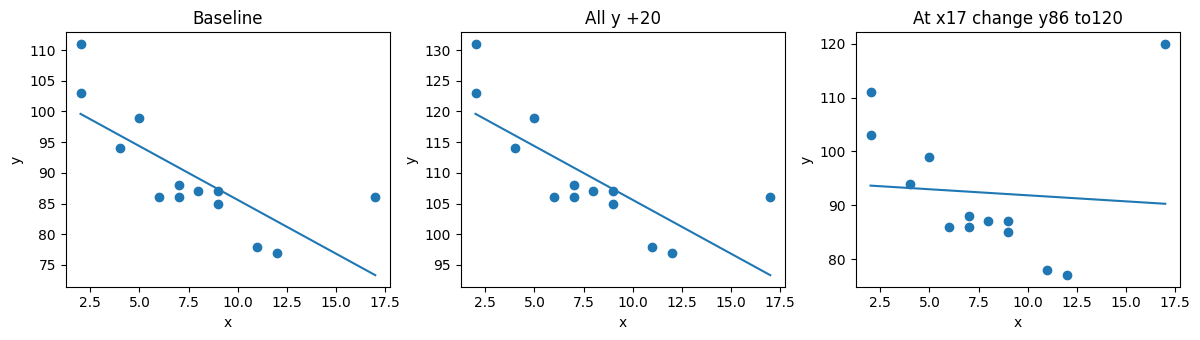

In [4]:
from scipy.stats import pearsonr, linregress
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
x = np.array([5, 7, 8, 7, 2, 17, 2, 9, 4, 11, 12, 9, 6])
y = np.array([99, 86, 87, 88, 111, 86, 103, 87, 94, 78, 77, 85, 86])
changed = y.copy()
changed[5] = 120
results['linear'] = {}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (name, v) in zip(axes, {'Baseline': y, 'All y +20': y + 20, 'At x17 change y86 to120': changed}.items()):
    fit = linregress(x, v)
    pred = fit.intercept + fit.slope * x
    results['linear'][name] = {'slope': float(fit.slope), 'intercept': float(fit.intercept), 'r': float(fit.rvalue), 'r2': float(r2_score(v, pred)), 'prediction10': float(fit.intercept + 10 * fit.slope)}
    ax.scatter(x, v)
    grid = np.array([2, 17])
    ax.plot(grid, fit.intercept + fit.slope * grid)
    ax.set(title=name, xlabel='x', ylabel='y')
plt.tight_layout()
plt.show()

## Results

R² values describe training fit. Where reported, leave-one-out RMSE measures held-out error in response units; lower values indicate smaller errors.

In [5]:
display(pd.DataFrame.from_dict(results['linear'], orient='index').rename(columns={'slope':'Slope','intercept':'Intercept','r':'Pearson r','r2':'Training R²','prediction10':'Prediction at x = 10'}).round(4))

,Slope,Intercept,Pearson r,Training R²,Prediction at x = 10
Baseline,-1.7513,103.1060,-0.7586,0.5755,85.5931
All y +20,-1.7513,123.1060,-0.7586,0.5755,105.5931
At x17 change y86 to120,-0.2252,94.0993,-0.0742,0.0055,91.8477


## Interpretation and limitations

The baseline predicts 85.5931 at x = 10. A uniform response shift changes only the intercept and predicted level. Altering the response at x = 17 reduces training R² from 0.5755 to 0.0055 and makes the fitted line almost horizontal. This sensitivity warrants investigation of influential observations and residual structure. The small sample and absence of held-out evaluation prevent claims about predictive reliability.

## Reproducibility

Cells were executed sequentially in an independent Python namespace. Outputs and plots are embedded, and library versions are recorded above. Analysis and editorial preparation used AI assistance.